<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lição 01 · Python: primeiros passos</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">05 · Pandas</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Series, DataFrames, ler, inspecionar, filtrar, transformar e agrupar dados</p>
</div>

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/01-python-as-ai-first-steps/blob/main/notebooks/05_Pandas/05_Pandas.ipynb) [![Slides](https://img.shields.io/badge/slides-Lição_01-ffd43b)](https://the-ai-learning-hub.github.io/01-python-as-ai-first-steps/#pandas)

## 🎯 Objetivos de aprendizagem

No fim deste notebook vais saber:

- explicar o que é o **pandas** e para que serve (uma folha de cálculo que se programa);
- criar e usar **Series** (uma coluna) e **DataFrames** (uma tabela);
- **ler** um ficheiro CSV e fazer a inspeção inicial de um conjunto de dados;
- **selecionar e filtrar** linhas e colunas com `[]`, `.loc`, `.iloc` e condições;
- **limpar e transformar** dados: criar colunas, ordenar, tratar valores em falta e duplicados;
- **agrupar e resumir** com `groupby` e fazer os teus primeiros gráficos;
- aplicar tudo isto sozinho a um conjunto de dados novo: **os passageiros do Titanic**.

**⏱️ Duração estimada:** 3h (com exercícios) · **📋 Pré-requisitos:** [04 · Módulos, Erros e Classes](../04_Modules_Errors_Classes/04_Modules_Errors_Classes.ipynb) · **▶️ Como usar:** executa cada célula com `Shift`+`Enter`, por ordem.

## 📑 Índice

1. [O que é o pandas](#sec-1)
    1. [Uma folha de cálculo programável](#sec-1-1)
    2. [Importar o pandas](#sec-1-2)
2. [Series: uma coluna de dados](#sec-2)
    1. [Criar uma Series](#sec-2-1)
    2. [Contas sem ciclos](#sec-2-2)
    3. [Estatísticas rápidas](#sec-2-3)
3. [DataFrame: uma tabela](#sec-3)
    1. [Criar um DataFrame a partir de um dicionário](#sec-3-1)
    2. [Anatomia de um DataFrame](#sec-3-2)
    3. [Uma coluna ou uma tabela?](#sec-3-3)
4. [Ler dados de ficheiros](#sec-4)
    1. [Formatos suportados](#sec-4-1)
    2. [O nosso dataset: pinguins da Antártida](#sec-4-2)
5. [Inspecionar: os primeiros 5 minutos](#sec-5)
    1. [Olhar para a tabela](#sec-5-1)
    2. [Tipos e valores em falta](#sec-5-2)
    3. [Estatísticas e contagens](#sec-5-3)
6. [Selecionar e filtrar](#sec-6)
    1. [Escolher colunas](#sec-6-1)
    2. [`.loc` e `.iloc`](#sec-6-2)
    3. [Filtrar linhas com condições](#sec-6-3)
    4. [`isin`, `between` e texto](#sec-6-4)
7. [Limpar e transformar](#sec-7)
    1. [Criar colunas novas](#sec-7-1)
    2. [Valores em falta](#sec-7-2)
    3. [Alterar algumas linhas com `.loc`](#sec-7-3)
    4. [Aplicar uma função com `.apply`](#sec-7-4)
    5. [Ordenar](#sec-7-5)
    6. [Renomear e remover colunas](#sec-7-6)
    7. [Duplicados e formatos errados](#sec-7-7)
8. [Agrupar e resumir](#sec-8)
    1. [`groupby`](#sec-8-1)
    2. [Várias estatísticas com `agg`](#sec-8-2)
    3. [Tabelas-resumo](#sec-8-3)
    4. [Primeiros gráficos](#sec-8-4)
9. [Exercícios finais: investiga o Titanic](#sec-9)
    1. [Conhecer os dados](#sec-9-1)
    2. [Quem sobreviveu?](#sec-9-2)
    3. [Limpar e criar colunas](#sec-9-3)
    4. [Primeiros gráficos](#sec-9-4)
10. [🏆 Desafio extra: dados reais e sujos](#sec-10)

[🏋️ Praticar mais](#praticar) · [📌 Resumo](#resumo)

## ⚙️ Preparação

Esta célula garante que os três ficheiros de dados existem na pasta `data/` (no Google Colab são descarregados automaticamente).

In [1]:
# Garante que os ficheiros de dados existem (necessário no Google Colab)
from pathlib import Path
import urllib.request

BASE = "https://raw.githubusercontent.com/the-ai-learning-hub/01-python-as-ai-first-steps/main/notebooks/05_Pandas/data/"
Path("data").mkdir(exist_ok=True)
for nome in ["penguins.csv", "titanic.csv", "classics.csv"]:
    if not Path("data", nome).exists():
        urllib.request.urlretrieve(BASE + nome, Path("data", nome))
print("Dados prontos ✅")

Dados prontos ✅


<a id="sec-1"></a>

# 1. O que é o pandas

<a id="sec-1-1"></a>

## 1.1. Uma folha de cálculo programável

O **pandas** é a biblioteca de Python mais usada para trabalhar com **dados em tabela** — linhas e colunas, como numa folha de Excel.
A diferença é que, em vez de clicares, **escreves os passos em código**. Isso traz três vantagens:

- **repetível:** amanhã chegam dados novos? Executas o mesmo notebook e pronto;
- **escala:** um milhão de linhas não assusta o pandas (o Excel começa a sofrer);
- **documentado:** o código é o registo exato do que fizeste aos dados.

Quase todas as análises seguem o mesmo ciclo — e é essa a estrutura deste notebook:

| Passo | Pergunta | Ferramentas pandas |
|---|---|---|
| **LER** | Onde estão os dados? | `pd.read_csv`, `pd.read_excel` |
| **INSPECIONAR** | Como são os dados? Falta alguma coisa? | `head`, `info`, `describe`, `isna` |
| **LIMPAR E TRANSFORMAR** | Que linhas e colunas me interessam? Há erros? | `[]`, `.loc`, filtros, `fillna`, colunas novas |
| **ANALISAR** | O que dizem os dados? | `value_counts`, `groupby`, `plot` |

> 🤖 **Ligação à IA:** antes de treinar qualquer modelo de *machine learning*, os dados passam quase sempre por um DataFrame do pandas.

<a id="sec-1-2"></a>

## 1.2. Importar o pandas

Como viste no notebook 04, importamos uma biblioteca com `import`. Por convenção (toda a gente faz assim!), o pandas é importado com o nome curto `pd`.

In [2]:
import pandas as pd

print(pd.__version__)

3.1.1


> 📝 **Nota:** o pandas já está instalado no teu ambiente (veio com `uv sync`). Num projeto novo, instalarias com `uv add pandas`.

> 📚 **Saber mais:** [W3Schools — Introdução ao pandas](https://www.w3schools.com/python/pandas/default.asp)

<a id="sec-2"></a>

# 2. Series: uma coluna de dados

Ao longo deste notebook **somos investigadores numa estação científica na Antártida** 🐧 e estudamos pinguins. Vamos começar com poucos dados, escritos à mão.

Uma **Series** é uma **coluna** de dados: uma sequência de valores, cada um com uma **etiqueta** (o *índice*).

<a id="sec-2-1"></a>

## 2.1. Criar uma Series

Pesámos quatro pinguins (em gramas). A partir de uma **lista**, o pandas numera as posições automaticamente (0, 1, 2, …):

In [3]:
pesos = pd.Series([3750, 3800, 3250, 5200])
pesos

0    3750
1    3800
2    3250
3    5200
dtype: int64

Repara nas duas colunas da saída: à esquerda o **índice**, à direita os **valores**. Em baixo, o `dtype` diz o tipo dos valores (`int64` = números inteiros).

Demos nomes aos pinguins. A partir de um **dicionário** (notebook 02), as chaves passam a ser o índice — muito mais legível:

In [4]:
pesos = pd.Series({
    "Pingu": 3750,
    "Neve": 3800,
    "Gelo": 3250,
    "Tux": 5200,
})
pesos

Pingu    3750
Neve     3800
Gelo     3250
Tux      5200
dtype: int64

In [5]:
print(pesos["Tux"])       # aceder pela etiqueta, como num dicionário
print(pesos.index)        # as etiquetas
print(pesos.values)       # os valores

5200
Index(['Pingu', 'Neve', 'Gelo', 'Tux'], dtype='str')
[3750 3800 3250 5200]


<a id="sec-2-2"></a>

## 2.2. Contas sem ciclos

Queremos os pesos em **quilogramas**. No notebook 03 terias escrito um ciclo `for`. Com uma Series **não é preciso ciclo**: a conta aplica-se a **todos os valores de uma vez** (diz-se que é uma operação *vetorizada*).

In [6]:
# Com um ciclo (notebook 03)
quilos_lista = []
for p in [3750, 3800, 3250, 5200]:
    quilos_lista.append(p / 1000)
print(quilos_lista)

# Com pandas: sem ciclo!
pesos / 1000

[3.75, 3.8, 3.25, 5.2]


Pingu    3.75
Neve     3.80
Gelo     3.25
Tux      5.20
dtype: float64

In [7]:
# Também funciona com comparações: o resultado é uma Series de True/False
pesos > 3500

Pingu     True
Neve      True
Gelo     False
Tux       True
dtype: bool

> 💡 **Dica:** sempre que te apetecer escrever um `for` sobre os valores de uma coluna, pergunta primeiro: "dá para fazer a conta de uma vez?" Quase sempre dá — e é muito mais rápido.

<a id="sec-2-3"></a>

## 2.3. Estatísticas rápidas

Uma Series traz métodos para as perguntas mais comuns:

In [8]:
print("Peso médio:", pesos.mean())
print("Peso máximo:", pesos.max())
print("O mais pesado:", pesos.idxmax())   # a etiqueta do máximo
print("Soma:", pesos.sum())

Peso médio: 4000.0
Peso máximo: 5200
O mais pesado: Tux
Soma: 16000


Para **texto que se repete** (categorias), o método mais útil é `value_counts()`: conta quantas vezes aparece cada valor, do mais frequente para o menos frequente.

In [9]:
especies = pd.Series(["Adelie", "Gentoo", "Adelie", "Chinstrap", "Adelie", "Gentoo"])
especies.value_counts()

Adelie       3
Gentoo       2
Chinstrap    1
Name: count, dtype: int64

### ✏️ Exercício 1 — Ninhos por ilha
**Dificuldade:** ⭐

Contámos os ninhos em três ilhas. Cria uma Series `ninhos` a partir do dicionário `{"Biscoe": 120, "Dream": 90, "Torgersen": 30}`.
Depois, mostra:
1. a média de ninhos por ilha;
2. o nome da ilha com mais ninhos;
3. quantos ninhos esperamos no próximo ano se cada ilha tiver **o dobro** (sem ciclo!).

Saída esperada: `80.0`, `Biscoe`, e os valores `240, 180, 60`.

In [10]:
ninhos = pd.Series({"Biscoe": 120, "Dream": 90, "Torgersen": 30})

# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
ninhos = pd.Series({"Biscoe": 120, "Dream": 90, "Torgersen": 30})

print(ninhos.mean())     # 80.0
print(ninhos.idxmax())   # Biscoe
print(ninhos * 2)        # multiplica todos os valores por 2
```

`ninhos * 2` aplica-se a cada valor e devolve uma Series **nova** (a original não muda).
</details>

> 📚 **Saber mais:** [W3Schools — Pandas Series](https://www.w3schools.com/python/pandas/pandas_series.asp)

<a id="sec-3"></a>

# 3. DataFrame: uma tabela

Um **DataFrame** é uma **tabela**: várias Series (colunas) lado a lado, que partilham o mesmo índice (as linhas).

<a id="sec-3-1"></a>

## 3.1. Criar um DataFrame a partir de um dicionário

A forma mais simples de criar um DataFrame é com **um dicionário de colunas** (notebook 02): cada chave é o nome de uma coluna e cada valor é a lista com os dados dessa coluna.

In [11]:
diario = pd.DataFrame({
    "nome": ["Pingu", "Neve", "Gelo", "Tux"],
    "especie": ["Adelie", "Adelie", "Chinstrap", "Gentoo"],
    "ilha": ["Torgersen", "Dream", "Dream", "Biscoe"],
    "peso_g": [3750, 3800, 3250, 5200],
})
diario

,nome,especie,ilha,peso_g
0,Pingu,Adelie,Torgersen,3750
1,Neve,Adelie,Dream,3800
2,Gelo,Chinstrap,Dream,3250
3,Tux,Gentoo,Biscoe,5200


Cada **linha** é um pinguim e cada **coluna** é uma característica. Esta é a forma "arrumada" de guardar dados — e a que vais encontrar quase sempre.

> ⚠️ **Cuidado:** todas as listas têm de ter o **mesmo tamanho**. Se uma tiver 3 elementos e as outras 4, o pandas dá `ValueError: All arrays must be of the same length`.

<a id="sec-3-2"></a>

## 3.2. Anatomia de um DataFrame

Estes atributos (sem parênteses — não são métodos!) respondem às perguntas básicas sobre uma tabela:

In [12]:
print("Forma (linhas, colunas):", diario.shape)
print("Colunas:", list(diario.columns))
print()
print(diario.dtypes)

Forma (linhas, colunas): (4, 4)
Colunas: ['nome', 'especie', 'ilha', 'peso_g']

nome         str
especie      str
ilha         str
peso_g     int64
dtype: object


Os tipos (`dtypes`) mais comuns:

| dtype | Significado | Exemplo |
|---|---|---|
| `int64` | números inteiros | `3750` |
| `float64` | números decimais (e `NaN`, "valor em falta") | `39.1` |
| `str` | texto | `"Adelie"` |
| `bool` | verdadeiro/falso | `True` |

<a id="sec-3-3"></a>

## 3.3. Uma coluna ou uma tabela?

Para obter uma coluna usa-se `df["nome"]` — tal como num dicionário. O resultado é uma **Series**.

In [13]:
pesos_diario = diario["peso_g"]
print(type(pesos_diario))
pesos_diario

<class 'pandas.Series'>


0    3750
1    3800
2    3250
3    5200
Name: peso_g, dtype: int64

Com **parênteses retos duplos** — `df[["nome"]]` — passas uma **lista** de colunas, e o resultado é um **DataFrame** (mesmo que tenha só uma coluna):

In [14]:
tabela = diario[["nome", "peso_g"]]
print(type(tabela))
tabela

<class 'pandas.DataFrame'>


,nome,peso_g
0,Pingu,3750
1,Neve,3800
2,Gelo,3250
3,Tux,5200


> ⚠️ **Cuidado:** `df["peso_g"]` (Series) e `df[["peso_g"]]` (DataFrame) parecem iguais, mas não são. Se um método "não existe" ou o resultado tem um aspeto estranho, confirma quantos `[` usaste.

### ✏️ Exercício 2 — O teu diário de campo
**Dificuldade:** ⭐

Cria um DataFrame `meu_diario` com **3 pinguins** inventados por ti e as colunas `nome`, `especie` e `peso_g`.
Depois mostra a sua forma (`shape`) e o **peso médio**.

Exemplo de saída: `(3, 3)` e `4000.0`.

In [15]:
meu_diario = pd.DataFrame({
    # escreve aqui as tuas colunas, por exemplo "nome": [...],
})

print(meu_diario.shape)

(0, 0)


<details>
<summary>💡 Ver solução</summary>

```python
meu_diario = pd.DataFrame({
    "nome": ["Flipper", "Bolinha", "Capitão"],
    "especie": ["Gentoo", "Adelie", "Chinstrap"],
    "peso_g": [5000, 3400, 3600],
})

print(meu_diario.shape)               # (3, 3)
print(meu_diario["peso_g"].mean())    # 4000.0
```

`meu_diario["peso_g"]` devolve uma Series, e as Series sabem calcular a média com `.mean()`.
</details>

> 📚 **Saber mais:** [W3Schools — Pandas DataFrames](https://www.w3schools.com/python/pandas/pandas_dataframes.asp)

<a id="sec-4"></a>

# 4. Ler dados de ficheiros

Na prática raramente escreves os dados à mão: lês um ficheiro. O pandas tem uma função `pd.read_...` para cada formato.

<a id="sec-4-1"></a>

## 4.1. Formatos suportados

| Formato | Função | Exemplo |
|---|---|---|
| CSV (texto separado por vírgulas) | `pd.read_csv` | `pd.read_csv("data/vendas.csv")` |
| Excel | `pd.read_excel` | `pd.read_excel("data/vendas.xlsx")` |
| JSON | `pd.read_json` | `pd.read_json("data/vendas.json")` |

E para guardar há o caminho inverso: `df.to_csv(...)`, `df.to_excel(...)`, …

Um ficheiro **CSV** é só texto: a primeira linha tem os nomes das colunas e cada linha seguinte é uma linha da tabela, com os valores separados por vírgulas:

```text
species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
Adelie,Torgersen,39.1,18.7,181,3750,MALE
Adelie,Torgersen,39.5,17.4,186,3800,FEMALE
```

> ⚠️ **Cuidado:** se vires caracteres estranhos como `Ã©` em vez de `é`, o problema é a **codificação** do ficheiro: experimenta `pd.read_csv("ficheiro.csv", encoding="utf-8")`. E se o separador for `;` (comum em Portugal), usa `sep=";"`.

<a id="sec-4-2"></a>

## 4.2. O nosso dataset: pinguins da Antártida

Agora sim, dados a sério! O dataset [**Palmer Penguins**](https://allisonhorst.github.io/palmerpenguins/) tem medições de **344 pinguins** de três espécies (*Adelie*, *Chinstrap* e *Gentoo*), feitas entre 2007 e 2009 em três ilhas perto da estação científica Palmer, na Antártida.

Os nomes das colunas estão em inglês (como na maioria dos dados que vais encontrar):

| Coluna | Significado |
|---|---|
| `species` | espécie |
| `island` | ilha onde o pinguim foi observado |
| `bill_length_mm` | comprimento do bico (mm) |
| `bill_depth_mm` | altura do bico (mm) |
| `flipper_length_mm` | comprimento da barbatana (asa) (mm) |
| `body_mass_g` | massa corporal (g) |
| `sex` | sexo (`MALE` / `FEMALE`) |

In [16]:
pinguins = pd.read_csv("data/penguins.csv")
pinguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


O Jupyter mostra só as primeiras e as últimas linhas — e no fundo diz o tamanho total: `344 rows × 7 columns`.

> 📚 **Saber mais:** [W3Schools — Ler ficheiros CSV](https://www.w3schools.com/python/pandas/pandas_csv.asp)

<a id="sec-5"></a>

# 5. Inspecionar: os primeiros 5 minutos

Antes de qualquer análise, gasta 5 minutos a **conhecer os dados**. Estes comandos são sempre os mesmos — vale a pena decorá-los.

<a id="sec-5-1"></a>

## 5.1. Olhar para a tabela

In [17]:
pinguins.head()     # as 5 primeiras linhas (pinguins.head(10) mostra 10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [18]:
pinguins.tail(3)    # as 3 últimas linhas

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,MALE


In [19]:
print(pinguins.shape)              # (linhas, colunas)
print(pinguins.columns.tolist())   # os nomes das colunas, numa lista

(344, 7)
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


<a id="sec-5-2"></a>

## 5.2. Tipos e valores em falta

`info()` é provavelmente o comando mais útil de todos: mostra cada coluna, quantos valores **não nulos** (preenchidos) tem e o seu tipo.

In [20]:
pinguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


Repara: há 344 linhas, mas a coluna `sex` só tem 333 valores preenchidos. Faltam dados!

> ⚠️ **Cuidado:** `info()` **imprime** o resumo diretamente e devolve `None`. Por isso, não escrevas `print(pinguins.info())` — vais ver um `None` perdido no fim.

Para contar os valores em falta (`NaN`, *Not a Number*) por coluna, combina `isna()` (dá `True` onde falta) com `sum()` (cada `True` conta 1):

In [21]:
pinguins.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Quais são os pinguins sem massa corporal? Uma "espreitadela" (vais perceber este código na secção 6):

In [22]:
pinguins[pinguins["body_mass_g"].isna()]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


São 2 pinguins que foram registados mas **não chegaram a ser medidos**. Vamos tratar destes casos na secção 7.

<a id="sec-5-3"></a>

## 5.3. Estatísticas e contagens

In [23]:
pinguins.describe()     # estatísticas das colunas numéricas

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Como ler o `describe()`:

- `count`: quantos valores preenchidos; `mean`: a média; `std`: o quanto os valores variam;
- `min` / `max`: o menor e o maior valor; `50%`: a **mediana** (o valor do meio).

Por exemplo: o pinguim mais leve tem 2,7 kg e o mais pesado 6,3 kg. Valores plausíveis — bom sinal! Quando um `min` ou `max` parece impossível (um pinguim com 0 g?), encontraste um problema nos dados.

In [24]:
print(pinguins["species"].unique())     # os valores distintos
print(pinguins["species"].nunique())    # quantos valores distintos

<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str
3


In [25]:
pinguins["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

### ✏️ Exercício 3 — Pinguins por ilha
**Dificuldade:** ⭐

Responde a duas perguntas sobre a coluna `island`:
1. Em quantas ilhas diferentes foram observados pinguins?
2. Quantos pinguins foram observados em cada ilha?

Saída esperada: `3`, e a ilha `Biscoe` com 168 pinguins à cabeça.

In [26]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
print(pinguins["island"].nunique())   # 3
pinguins["island"].value_counts()     # Biscoe 168, Dream 124, Torgersen 52
```

`nunique()` conta os valores distintos e `value_counts()` conta quantas vezes aparece cada um, do mais frequente para o menos frequente.
</details>

> 📚 **Saber mais:** [W3Schools — Analisar DataFrames](https://www.w3schools.com/python/pandas/pandas_analyzing.asp)

<a id="sec-6"></a>

# 6. Selecionar e filtrar

<a id="sec-6-1"></a>

## 6.1. Escolher colunas

Já viste na secção 3: uma coluna com `[]`, várias colunas com `[[]]`.

In [27]:
pinguins["species"].head()     # uma coluna → Series

0    Adelie
1    Adelie
2    Adelie
3    Adelie
4    Adelie
Name: species, dtype: str

In [28]:
pinguins[["species", "island", "body_mass_g"]].head()     # lista de colunas → DataFrame

,species,island,body_mass_g
0,Adelie,Torgersen,3750.0
1,Adelie,Torgersen,3800.0
2,Adelie,Torgersen,3250.0
3,Adelie,Torgersen,NaN
4,Adelie,Torgersen,3450.0


<a id="sec-6-2"></a>

## 6.2. `.loc` e `.iloc`

Para escolher **linhas e colunas ao mesmo tempo**, há duas ferramentas:

| | Seleciona por… | Exemplo | Fim do intervalo |
|---|---|---|---|
| `.loc[linhas, colunas]` | **etiquetas** (nomes) | `pinguins.loc[0:2, "species"]` | **incluído** |
| `.iloc[linhas, colunas]` | **posições** (números, como nas listas) | `pinguins.iloc[0:2, 0]` | excluído |

In [29]:
# .loc: linhas com etiqueta 0 a 2 (inclusive!) e duas colunas pelo nome
pinguins.loc[0:2, ["species", "body_mass_g"]]

,species,body_mass_g
0,Adelie,3750.0
1,Adelie,3800.0
2,Adelie,3250.0


In [30]:
# .iloc: as 3 primeiras linhas (posições 0, 1, 2) e as 2 primeiras colunas
pinguins.iloc[0:3, 0:2]

,species,island
0,Adelie,Torgersen
1,Adelie,Torgersen
2,Adelie,Torgersen


In [31]:
# Um único valor: linha 0, coluna "body_mass_g"
print(pinguins.loc[0, "body_mass_g"])

3750.0


> ⚠️ **Cuidado:** com `.loc` o fim do intervalo **está incluído** (`0:2` dá 3 linhas); com `.iloc` não está (tal como nas listas do notebook 02). Aqui as etiquetas coincidem com as posições, mas depois de filtrar ou ordenar deixam de coincidir!

<a id="sec-6-3"></a>

## 6.3. Filtrar linhas com condições

Pergunta de investigação: **quais são os pinguins com mais de 5 kg?** Filtrar faz-se em dois passos:
1. escrever uma **condição** sobre uma coluna → dá uma Series de `True`/`False` (chama-se *máscara*);
2. passar essa máscara entre `[]` → ficam só as linhas onde é `True`.

In [32]:
mascara = pinguins["body_mass_g"] > 5000
print(mascara.head())
print("Pinguins com mais de 5 kg:", mascara.sum())    # cada True conta 1

0    False
1    False
2    False
3    False
4    False
Name: body_mass_g, dtype: bool
Pinguins com mais de 5 kg: 61


In [33]:
pesados = pinguins[mascara]
pesados.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE
224,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
227,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,MALE
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,MALE


Na prática escreve-se tudo numa linha. Para **combinar condições** usa `&` (e), `|` (ou) e `~` (não) — **não** `and`/`or`/`not` — e põe **cada condição entre parênteses**:

In [34]:
# Pinguins da espécie Adelie E da ilha Dream
pinguins[(pinguins["species"] == "Adelie") & (pinguins["island"] == "Dream")].head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
30,Adelie,Dream,39.5,16.7,178.0,3250.0,FEMALE
31,Adelie,Dream,37.2,18.1,178.0,3900.0,MALE
32,Adelie,Dream,39.5,17.8,188.0,3300.0,FEMALE
33,Adelie,Dream,40.9,18.9,184.0,3900.0,MALE
34,Adelie,Dream,36.4,17.0,195.0,3325.0,FEMALE


In [35]:
# Pinguins muito leves OU muito pesados
pinguins[(pinguins["body_mass_g"] < 3000) | (pinguins["body_mass_g"] > 6000)]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
54,Adelie,Biscoe,34.5,18.1,187.0,2900.0,FEMALE
58,Adelie,Biscoe,36.5,16.6,181.0,2850.0,FEMALE
64,Adelie,Biscoe,36.4,17.1,184.0,2850.0,FEMALE
98,Adelie,Dream,33.1,16.1,178.0,2900.0,FEMALE
104,Adelie,Biscoe,37.9,18.6,193.0,2925.0,FEMALE
116,Adelie,Torgersen,38.6,17.0,188.0,2900.0,FEMALE
174,Chinstrap,Dream,43.2,16.6,187.0,2900.0,FEMALE
190,Chinstrap,Dream,46.9,16.6,192.0,2700.0,FEMALE
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,MALE


> ⚠️ **Cuidado:** os parênteses são obrigatórios. Sem eles, `pinguins["species"] == "Adelie" & pinguins["island"] == "Dream"` dá erro, porque o Python calcula primeiro `"Adelie" & pinguins["island"]`. E `and` em vez de `&` dá `ValueError: The truth value of a Series is ambiguous`.

<a id="sec-6-4"></a>

## 6.4. `isin`, `between` e texto

Alguns atalhos muito úteis para construir condições:

In [36]:
# isin: o valor está nesta lista? (em vez de vários == ligados com |)
pinguins[pinguins["island"].isin(["Dream", "Torgersen"])]["island"].value_counts()

island
Dream        124
Torgersen     52
Name: count, dtype: int64

In [37]:
# between: está entre dois valores? (os limites estão incluídos)
medios = pinguins[pinguins["body_mass_g"].between(3000, 3500)]
print("Pinguins entre 3 e 3,5 kg:", len(medios))

Pinguins entre 3 e 3,5 kg: 69


Para colunas de texto existe o acessor **`.str`**, que aplica métodos de strings (notebook 01) a **todos** os valores da coluna:

In [38]:
# Ilhas cujo nome começa por "T"
pinguins[pinguins["island"].str.startswith("T")]["island"].unique()

<StringArray>
['Torgersen']
Length: 1, dtype: str

In [39]:
pinguins["species"].str.upper().head(3)

0    ADELIE
1    ADELIE
2    ADELIE
Name: species, dtype: str

> ⚠️ **Cuidado:** `.str.contains("MALE")` procura um **pedaço** de texto — e `"FEMALE"` também contém `"MALE"`! Para uma correspondência exata, usa `==`. Além disso, se a coluna tiver valores em falta, junta `na=False` (trata-os como "não contém").

In [40]:
print("Com contains:", pinguins["sex"].str.contains("MALE", na=False).sum())   # apanha MALE e FEMALE!
print("Com ==      :", (pinguins["sex"] == "MALE").sum())                       # só os machos

Com contains: 333
Com ==      : 168


### ✏️ Exercício 4 — Bicos compridos na ilha Dream
**Dificuldade:** ⭐⭐

Cria `bicos_dream` com os pinguins da ilha `"Dream"` **e** com bico (`bill_length_mm`) maior do que 50 mm.
Mostra quantos são e quais as espécies (com `value_counts()`).

Devem ser **30** pinguins, todos da espécie *Chinstrap*.

In [41]:
bicos_dream = pinguins.head(0)   # substitui esta linha pelo teu filtro

print(len(bicos_dream))

0


<details>
<summary>💡 Ver solução</summary>

```python
bicos_dream = pinguins[(pinguins["island"] == "Dream") & (pinguins["bill_length_mm"] > 50)]

print(len(bicos_dream))   # 30
bicos_dream["species"].value_counts()
```

Duas condições, cada uma entre parênteses, ligadas com `&`. O `value_counts()` mostra que bicos compridos na ilha Dream são uma "assinatura" dos *Chinstrap*.
</details>

> 📚 **Saber mais:** [W3Schools — Pandas DataFrames (localizar linhas)](https://www.w3schools.com/python/pandas/pandas_dataframes.asp)

<a id="sec-7"></a>

# 7. Limpar e transformar

Agora vamos **mudar** os dados: criar colunas, tratar o que falta, ordenar. Para não estragarmos os dados originais, trabalhamos numa **cópia**.

In [42]:
dados = pinguins.copy()

<a id="sec-7-1"></a>

## 7.1. Criar colunas novas

Cria-se uma coluna atribuindo a um nome novo — e as contas são feitas linha a linha, sem ciclos:

In [43]:
dados["massa_kg"] = dados["body_mass_g"] / 1000
dados["bico_ratio"] = dados["bill_length_mm"] / dados["bill_depth_mm"]   # bico comprido e fino → valor alto
dados[["species", "body_mass_g", "massa_kg", "bico_ratio"]].head()

,species,body_mass_g,massa_kg,bico_ratio
0,Adelie,3750.0,3.75,2.090909
1,Adelie,3800.0,3.80,2.270115
2,Adelie,3250.0,3.25,2.238889
3,Adelie,NaN,NaN,NaN
4,Adelie,3450.0,3.45,1.901554


In [44]:
# Uma coluna também pode ser o resultado de uma condição (True/False)
dados["pesado"] = dados["body_mass_g"] > 4500
dados["pesado"].value_counts()

pesado
False    229
True     115
Name: count, dtype: int64

<a id="sec-7-2"></a>

## 7.2. Valores em falta

Os valores em falta aparecem como `NaN`. Há duas estratégias principais:
- **remover** as linhas com `dropna()` — ou `dropna(subset=[colunas])` para olhar só para algumas colunas;
- **preencher** com `fillna(valor)`.

Os 2 pinguins sem medições não nos servem para nada → removemos:

In [45]:
print("Antes:", len(dados))
dados = dados.dropna(subset=["body_mass_g"])
print("Depois:", len(dados))

Antes: 344
Depois: 342


Os restantes pinguins sem `sex` têm todas as medições — é pena deitá-los fora. Preenchemos o sexo com `"desconhecido"`:

In [46]:
print("Sem sexo, antes:", dados["sex"].isna().sum())
dados["sex"] = dados["sex"].fillna("desconhecido")
print("Sem sexo, depois:", dados["sex"].isna().sum())
dados["sex"].value_counts()

Sem sexo, antes:

 9
Sem sexo, depois: 0


sex
MALE            168
FEMALE          165
desconhecido      9
Name: count, dtype: int64

> 💡 **Dica:** remover ou preencher é uma **decisão** sobre os dados, não só sobre código. Pergunta sempre: quantas linhas perco? O valor que vou inventar é razoável? Para números, é comum preencher com a **mediana** da coluna: `df["col"].fillna(df["col"].median())`.

> 📝 **Nota:** `dropna` e `fillna` **devolvem um DataFrame/Series novo**. Por isso escrevemos `dados = dados.dropna(...)` — sem a atribuição, nada mudava.

<a id="sec-7-3"></a>

## 7.3. Alterar algumas linhas com `.loc`

Queremos o sexo em português. Para alterar **só algumas linhas** de uma coluna, usa **`.loc[condição, coluna] = valor`**:

In [47]:
dados.loc[dados["sex"] == "MALE", "sex"] = "macho"
dados.loc[dados["sex"] == "FEMALE", "sex"] = "fêmea"

dados["sex"].value_counts()

sex
macho           168
fêmea           165
desconhecido      9
Name: count, dtype: int64

> ⚠️ **Cuidado:** **não** escrevas `dados["sex"][condição] = valor` ("atribuição encadeada"). No pandas 3 isso **não altera** `dados` — a alteração perde-se numa cópia temporária. Usa sempre `.loc[condição, coluna] = valor`.

<a id="sec-7-4"></a>

## 7.4. Aplicar uma função com `.apply`

Quando a transformação é mais complicada do que uma conta, escreve uma **função** (notebook 01) e aplica-a a cada valor com `.apply`:

In [48]:
def tamanho(massa):
    """Classifica um pinguim pela massa corporal (em gramas)."""
    if massa < 3500:
        return "pequeno"
    elif massa < 4500:
        return "médio"
    else:
        return "grande"


dados["tamanho"] = dados["body_mass_g"].apply(tamanho)
dados[["species", "body_mass_g", "tamanho"]].head()

,species,body_mass_g,tamanho
0,Adelie,3750.0,médio
1,Adelie,3800.0,médio
2,Adelie,3250.0,pequeno
4,Adelie,3450.0,pequeno
5,Adelie,3650.0,médio


> 💡 **Dica:** passas o **nome** da função (`tamanho`), sem parênteses — é o pandas que a chama, uma vez por valor. Usa `.apply` só quando não há uma conta direta: é bastante mais lento.

> ⚠️ **Cuidado:** fizemos isto **depois** de remover os `NaN`. Com um `NaN`, `massa < 3500` e `massa < 4500` são ambos `False`, e um pinguim sem medições seria classificado como "grande"!

<a id="sec-7-5"></a>

## 7.5. Ordenar

`sort_values` ordena pela coluna que indicares (`ascending=False` para ordem decrescente):

In [49]:
dados.sort_values("body_mass_g", ascending=False)[["species", "sex", "body_mass_g"]].head()

,species,sex,body_mass_g
237,Gentoo,macho,6300.0
253,Gentoo,macho,6050.0
337,Gentoo,macho,6000.0
297,Gentoo,macho,6000.0
299,Gentoo,macho,5950.0


> ⚠️ **Cuidado:** `sort_values` (tal como `rename`, `drop`, `fillna`…) **devolve um DataFrame novo** e não altera o original. Se escreveres só `dados.sort_values("body_mass_g")`, `dados` continua igual. Para guardar o resultado: `dados = dados.sort_values("body_mass_g")`.

<a id="sec-7-6"></a>

## 7.6. Renomear e remover colunas

`rename(columns={antigo: novo})` muda nomes de colunas e `drop(columns=[...])` remove colunas. Ambos devolvem um DataFrame novo:

In [50]:
em_portugues = dados.rename(columns={"species": "especie", "island": "ilha", "sex": "sexo"})
em_portugues.columns.tolist()

['especie',
 'ilha',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sexo',
 'massa_kg',
 'bico_ratio',
 'pesado',
 'tamanho']

In [51]:
dados = dados.drop(columns=["pesado", "bico_ratio"])
dados.columns.tolist()

['species',
 'island',
 'bill_length_mm',
 'bill_depth_mm',
 'flipper_length_mm',
 'body_mass_g',
 'sex',
 'massa_kg',
 'tamanho']

<a id="sec-7-7"></a>

## 7.7. Duplicados e formatos errados

Mais dois problemas clássicos de limpeza de dados.

**Linhas duplicadas.** `duplicated()` marca com `True` as linhas que repetem uma anterior, e `drop_duplicates()` remove-as. Os nossos pinguins não têm duplicados:

In [52]:
print("Linhas duplicadas:", pinguins.duplicated().sum())

Linhas duplicadas: 0


Mas imagina que um colega registou o mesmo pinguim duas vezes no diário de campo:

In [53]:
registos = pd.DataFrame({
    "nome": ["Pingu", "Neve", "Pingu", "Tux"],
    "peso_g": [3750, 3800, 3750, 5200],
})
print("Duplicados:", registos.duplicated().sum())
registos.drop_duplicates()

Duplicados: 1


,nome,peso_g
0,Pingu,3750
1,Neve,3800
3,Tux,5200


**Formatos errados.** Às vezes uma coluna de números chega como **texto** (porque alguém escreveu `"n/d"` numa célula). `pd.to_numeric(..., errors="coerce")` converte o que consegue e põe `NaN` no que não consegue:

In [54]:
pesos_texto = pd.Series(["3750", "3800", "n/d", "5200", "balança avariada"])
print(pesos_texto.dtype)    # texto: não dá para fazer contas

pesos_num = pd.to_numeric(pesos_texto, errors="coerce")
print(pesos_num)
print("Média:", pesos_num.mean())    # a média ignora os NaN

str
0    3750.0
1    3800.0
2       NaN
3    5200.0
4       NaN
dtype: float64
Média: 4250.0


### ✏️ Exercício 5 — Barbatanas mais compridas
**Dificuldade:** ⭐⭐

Em `dados`:
1. cria a coluna `barbatana_cm` com o comprimento da barbatana em **centímetros** (`flipper_length_mm` ÷ 10);
2. ordena por `barbatana_cm` (do maior para o menor) e guarda em `ordenados`;
3. mostra a `species`, a `sex` e a `barbatana_cm` dos 3 primeiros.

O primeiro deve ser um *Gentoo* macho com 23,1 cm.

In [55]:
# escreve aqui o teu código
ordenados = dados.head(0)   # substitui esta linha

ordenados

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,massa_kg,tamanho


<details>
<summary>💡 Ver solução</summary>

```python
dados["barbatana_cm"] = dados["flipper_length_mm"] / 10
ordenados = dados.sort_values("barbatana_cm", ascending=False)

ordenados[["species", "sex", "barbatana_cm"]].head(3)
```

A divisão aplica-se a toda a coluna de uma vez. Como `sort_values` devolve um DataFrame novo, guardamos o resultado em `ordenados`.
</details>

> 📚 **Saber mais:** [W3Schools — Limpar dados](https://www.w3schools.com/python/pandas/pandas_cleaning.asp)

<a id="sec-8"></a>

# 8. Agrupar e resumir

<a id="sec-8-1"></a>

## 8.1. `groupby`

`groupby` responde a perguntas do tipo **"para cada X, qual é o Y?"** — por exemplo, "para cada espécie, qual é a massa média?". Funciona em três passos: **dividir** a tabela por grupos → **calcular** uma estatística em cada grupo → **juntar** os resultados.

In [56]:
# Para cada espécie, a massa média
dados.groupby("species")["body_mass_g"].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

Os *Gentoo* são claramente os maiores: pesam em média mais de 1 kg do que as outras espécies.

In [57]:
# Para cada sexo, o comprimento médio da barbatana (arredondado a 1 casa decimal)
dados.groupby("sex")["flipper_length_mm"].mean().round(1)

sex
desconhecido    199.0
fêmea           197.4
macho           204.5
Name: flipper_length_mm, dtype: float64

<a id="sec-8-2"></a>

## 8.2. Várias estatísticas com `agg`

Com `agg` calculas várias estatísticas de uma vez. A forma mais legível dá nomes às colunas do resultado: `nome_novo=(coluna, estatística)`.

In [58]:
resumo = dados.groupby("species").agg(
    pinguins=("species", "count"),
    massa_media=("body_mass_g", "mean"),
    massa_max=("body_mass_g", "max"),
    bico_medio=("bill_length_mm", "mean"),
)
resumo.round(1)

,pinguins,massa_media,massa_max,bico_medio
species,,,,
Adelie,151,3700.7,4775.0,38.8
Chinstrap,68,3733.1,4800.0,48.8
Gentoo,123,5076.0,6300.0,47.5


Estatísticas mais usadas: `"count"`, `"sum"`, `"mean"`, `"median"`, `"min"`, `"max"`.

<a id="sec-8-3"></a>

## 8.3. Tabelas-resumo

`pd.crosstab` **conta** as combinações de duas colunas (como uma tabela dinâmica do Excel):

In [59]:
# Que espécies vivem em que ilhas?
pd.crosstab(dados["species"], dados["island"])

island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


Uma descoberta: os *Gentoo* só aparecem na ilha Biscoe e os *Chinstrap* só na ilha Dream. Os *Adelie* estão nas três.

`pivot_table` faz o mesmo tipo de tabela, mas com **qualquer estatística** (por omissão, a média):

In [60]:
# Massa média para cada espécie × sexo
conhecidos = dados[dados["sex"] != "desconhecido"]
conhecidos.pivot_table(index="species", columns="sex", values="body_mass_g", aggfunc="mean").round(0)

sex,fêmea,macho
species,,
Adelie,3369.0,4043.0
Chinstrap,3527.0,3939.0
Gentoo,4680.0,5485.0


<a id="sec-8-4"></a>

## 8.4. Primeiros gráficos

Os DataFrames e as Series têm um método `.plot()` que usa o **Matplotlib** por baixo. É a forma mais rápida de *ver* os dados. No notebook 06 vais aprender a fazer gráficos com muito mais controlo — aqui ficamos pelo essencial: **um título, nomes nos eixos e nada de enfeites**.

In [61]:
import matplotlib.pyplot as plt

# Retira as linhas de cima e da direita do gráfico: não acrescentam informação
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Histograma:** como se distribuem as massas dos pinguins?

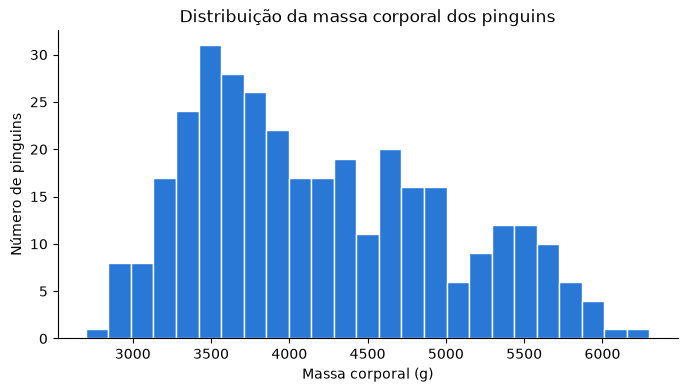

In [62]:
dados["body_mass_g"].plot(kind="hist", bins=25, color="#2a78d6", edgecolor="white", figsize=(8, 4))
plt.title("Distribuição da massa corporal dos pinguins")
plt.xlabel("Massa corporal (g)")
plt.ylabel("Número de pinguins")
plt.show()

**Barras:** a massa média de cada espécie (barras horizontais, ordenadas — mais fáceis de ler).

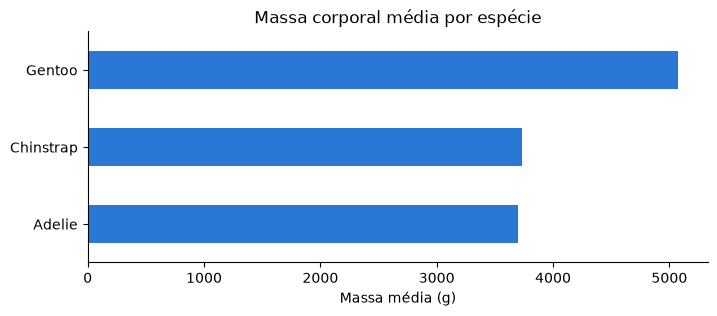

In [63]:
massa_especie = dados.groupby("species")["body_mass_g"].mean().sort_values()

massa_especie.plot(kind="barh", color="#2a78d6", figsize=(8, 3))
plt.title("Massa corporal média por espécie")
plt.xlabel("Massa média (g)")
plt.ylabel("")
plt.show()

**Dispersão:** pinguins com barbatanas maiores são mais pesados? Desenhamos cada espécie com a sua cor, filtrando uma de cada vez com um ciclo `for` (notebook 03):

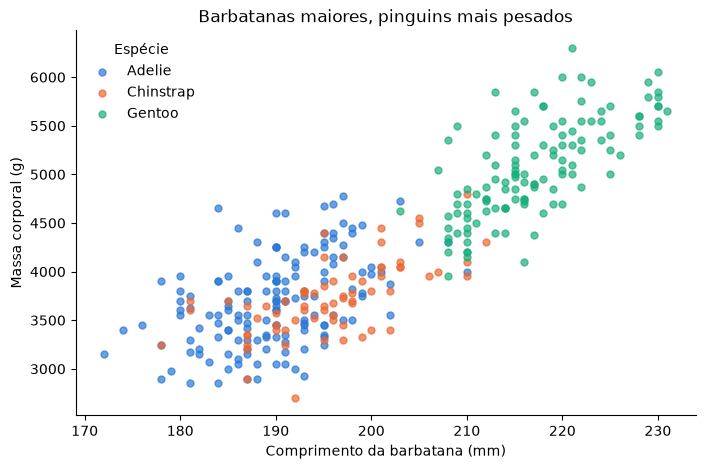

In [64]:
cores = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

plt.figure(figsize=(8, 5))
for especie, cor in cores.items():
    grupo = dados[dados["species"] == especie]
    plt.scatter(grupo["flipper_length_mm"], grupo["body_mass_g"], color=cor, label=especie, alpha=0.7, s=25)

plt.title("Barbatanas maiores, pinguins mais pesados")
plt.xlabel("Comprimento da barbatana (mm)")
plt.ylabel("Massa corporal (g)")
plt.legend(title="Espécie", frameon=False)
plt.show()

Sim: quanto maior a barbatana, mais pesado o pinguim — e as três espécies formam grupos bem visíveis.

> 💡 **Dica:** `kind=` escolhe o tipo de gráfico: `"line"`, `"bar"`, `"barh"`, `"hist"`, `"scatter"` (este precisa de `x=` e `y=`), `"box"`.

> 🤖 **Ligação à IA:** um modelo de *machine learning* consegue aprender a adivinhar a espécie de um pinguim a partir destas medições — precisamente porque as espécies formam grupos separados neste gráfico.

### ✏️ Exercício 6 — Resumo por ilha
**Dificuldade:** ⭐⭐

Usando `dados`, calcula para cada ilha (`island`):
- o número de pinguins (`pinguins`);
- a massa média (`massa_media`).

Guarda o resultado em `por_ilha`, arredondado a 1 casa decimal. A ilha `Biscoe` deve ter os pinguins mais pesados (perto de 4716 g, porque é lá que vivem os *Gentoo*).

In [65]:
por_ilha = None   # substitui por um groupby + agg

print(por_ilha)

None


<details>
<summary>💡 Ver solução</summary>

```python
por_ilha = dados.groupby("island").agg(
    pinguins=("species", "count"),
    massa_media=("body_mass_g", "mean"),
).round(1)

print(por_ilha)
```

`agg` com pares `(coluna, estatística)` cria uma coluna por estatística. Para contar pinguins, qualquer coluna sem valores em falta serve (usámos `species`).
</details>

### ✏️ Exercício 7 — Gráfico de barras: pinguins por espécie
**Dificuldade:** ⭐⭐

Faz um **gráfico de barras horizontais** com o número de pinguins de cada espécie, ordenado do maior para o menor (o maior em cima), com título e nome no eixo x.

> 💡 `value_counts()` já te dá as contagens; `.sort_values()` põe-nas por ordem crescente (o `barh` desenha de baixo para cima).

In [66]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
contagem = dados["species"].value_counts().sort_values()

contagem.plot(kind="barh", color="#2a78d6", figsize=(8, 3))
plt.title("Número de pinguins por espécie")
plt.xlabel("Número de pinguins")
plt.ylabel("")
plt.show()
```

Ordenar as barras torna a comparação imediata. Repara que basta uma cor: as barras já estão identificadas pelos nomes no eixo.
</details>

> 📚 **Saber mais:** [W3Schools — Gráficos com pandas](https://www.w3schools.com/python/pandas/pandas_plotting.asp)

<a id="sec-9"></a>

# 9. Exercícios finais: investiga o Titanic

Mudamos de cenário: deixamos a Antártida e vamos para o **Atlântico Norte, abril de 1912**. 🚢 O Titanic afundou na sua viagem inaugural e morreram mais de 1500 pessoas.

Vais usar tudo o que aprendeste para responder a uma pergunta: **quem teve mais hipóteses de sobreviver?** O ficheiro tem dados de **891 passageiros**:

| Coluna | Significado |
|---|---|
| `survived` | sobreviveu? (`1` = sim, `0` = não) |
| `pclass` / `class` | classe do bilhete: `1`/`First`, `2`/`Second`, `3`/`Third` |
| `sex` | sexo (`male` / `female`) |
| `age` | idade (anos) |
| `sibsp` | nº de irmãos/cônjuges a bordo |
| `parch` | nº de pais/filhos a bordo |
| `fare` | preço do bilhete (libras) |
| `embarked` / `embark_town` | porto de embarque (`S` = Southampton, `C` = Cherbourg, `Q` = Queenstown) |
| `who` | `man`, `woman` ou `child` |
| `adult_male` | é um homem adulto? (`True`/`False`) |
| `deck` | convés da cabine (A a G) |
| `alive` | igual a `survived`, mas em texto (`yes`/`no`) |
| `alone` | viajava sozinho? (`True`/`False`) |

A célula seguinte carrega os dados. Todos os exercícios usam esta variável `titanic`.

In [67]:
titanic = pd.read_csv("data/titanic.csv")
print("Dados carregados:", titanic.shape)

Dados carregados: (891, 15)


<a id="sec-9-1"></a>

## 9.1. Conhecer os dados

### ✏️ Exercício 8 — Primeiro contacto
**Dificuldade:** ⭐

Faz a inspeção inicial de `titanic`:
1. mostra as 5 primeiras linhas;
2. mostra o resumo das colunas (tipos e valores preenchidos) com `info()`.

Quantos passageiros e quantas colunas há? (Deves ver `891` linhas e `15` colunas.)

In [68]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
display(titanic.head())
titanic.info()
```

Numa célula, só a **última** expressão é mostrada automaticamente — por isso usamos `display()` (função do Jupyter) para mostrar a tabela do `head()`. O `info()` imprime sozinho.
</details>

### ✏️ Exercício 9 — Valores em falta
**Dificuldade:** ⭐

Conta quantos valores faltam em cada coluna e mostra **só** as colunas que têm algum valor em falta.

Devem aparecer 4 colunas: `age` (177), `embarked` (2), `deck` (688) e `embark_town` (2).

In [69]:
falta = None   # substitui pelo teu código

print(falta)

None


<details>
<summary>💡 Ver solução</summary>

```python
falta = titanic.isna().sum()

print(falta[falta > 0])
```

`isna().sum()` conta os `NaN` por coluna. Depois filtramos a própria Series com a condição `falta > 0`. A coluna `deck` está quase vazia (77% em falta!) — vamos tratar disso no exercício 16.
</details>

<a id="sec-9-2"></a>

## 9.2. Quem sobreviveu?

> 💡 **Truque:** a coluna `survived` só tem `0` e `1`. A **média** de uma coluna de zeros e uns é a **proporção de uns** — ou seja, a taxa de sobrevivência! Por exemplo, a média de `[1, 0, 0, 1]` é `0.5` = 50% sobreviveram.

### ✏️ Exercício 10 — Taxa de sobrevivência global
**Dificuldade:** ⭐

Que percentagem dos passageiros sobreviveu? Calcula também **quantos** sobreviveram.

Resultado esperado: `342` sobreviventes, cerca de `38.4` %.

In [70]:
taxa = 0   # substitui pelo teu código

print(round(taxa * 100, 1), "%")

0 %


<details>
<summary>💡 Ver solução</summary>

```python
taxa = titanic["survived"].mean()

print(titanic["survived"].sum(), "sobreviventes")   # 342
print(round(taxa * 100, 1), "%")                     # 38.4 %
```

A soma de uma coluna de 0 e 1 conta os uns (os sobreviventes); a média dá a proporção. Multiplicamos por 100 para ter a percentagem.
</details>

### ✏️ Exercício 11 — Mulheres e crianças primeiro?
**Dificuldade:** ⭐⭐

Calcula a taxa de sobrevivência **por sexo**.

Resultado esperado: `female` ≈ `0.742` e `male` ≈ `0.189`. Sobreviveram 74% das mulheres e só 19% dos homens!

In [71]:
por_sexo = None   # substitui por um groupby

print(por_sexo)

None


<details>
<summary>💡 Ver solução</summary>

```python
por_sexo = titanic.groupby("sex")["survived"].mean().round(3)

print(por_sexo)
```

"Para cada sexo, qual a média de `survived`?" — é exatamente o padrão do `groupby`. A regra "mulheres e crianças primeiro" foi mesmo aplicada nos botes salva-vidas.
</details>

### ✏️ Exercício 12 — A classe importava?
**Dificuldade:** ⭐⭐

Calcula a taxa de sobrevivência **por classe** (coluna `class`).

Resultado esperado: `First` ≈ `0.630`, `Second` ≈ `0.473`, `Third` ≈ `0.242`.

In [72]:
por_classe = None   # substitui por um groupby

print(por_classe)

None


<details>
<summary>💡 Ver solução</summary>

```python
por_classe = titanic.groupby("class")["survived"].mean().round(3)

print(por_classe)
```

Quanto melhor a classe, maior a taxa de sobrevivência: os passageiros de 1.ª classe tinham as cabines mais perto dos botes salva-vidas.
</details>

### ✏️ Exercício 13 — Quanto custava o bilhete?
**Dificuldade:** ⭐⭐

Para cada classe, calcula o preço **médio**, a **mediana** e o **máximo** do bilhete (`fare`), com colunas chamadas `media`, `mediana` e `maximo`, arredondado a 2 casas decimais.

Em 1.ª classe, a média deve ser `84.15` e o máximo `512.33` libras.

In [73]:
precos = None   # substitui por um groupby + agg

print(precos)

None


<details>
<summary>💡 Ver solução</summary>

```python
precos = titanic.groupby("class").agg(
    media=("fare", "mean"),
    mediana=("fare", "median"),
    maximo=("fare", "max"),
).round(2)

print(precos)
```

Repara que, em 1.ª classe, a média (84) é muito maior do que a mediana (60): alguns bilhetes caríssimos "puxam" a média para cima. A mediana é menos sensível a valores extremos.
</details>

### ✏️ Exercício 14 — Sexo × classe
**Dificuldade:** ⭐⭐

1. Com `pd.crosstab`, conta quantos passageiros há de cada sexo em cada classe.
2. Com `pivot_table`, calcula a **taxa de sobrevivência** para cada combinação sexo × classe (arredondada a 3 casas).

Deves descobrir que **97%** das mulheres da 1.ª classe sobreviveram, contra apenas **13,5%** dos homens da 3.ª.

In [74]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
display(pd.crosstab(titanic["sex"], titanic["class"]))

titanic.pivot_table(index="sex", columns="class", values="survived", aggfunc="mean").round(3)
```

O `crosstab` conta, o `pivot_table` calcula uma estatística (aqui a média de `survived`, ou seja, a taxa de sobrevivência). Juntando duas variáveis, as diferenças ficam ainda mais fortes.
</details>

### ✏️ Exercício 15 — Crianças, adolescentes e adultos
**Dificuldade:** ⭐⭐⭐

A coluna `age` é um número. Para comparar grupos de idade, usamos `pd.cut`, que **corta** uma coluna numérica em intervalos com nomes:

```python
pd.cut(titanic["age"], bins=[0, 12, 18, 100], labels=["criança", "adolescente", "adulto"])
```

`bins=[0, 12, 18, 100]` cria os intervalos 0–12, 12–18 e 18–100 (o limite da direita está incluído: quem tem 12 anos é criança).

1. Cria em `titanic` a coluna `grupo_idade` com o código acima;
2. calcula, para cada grupo, a taxa de sobrevivência e o número de passageiros (`agg` com `"mean"` e `"count"`).

As crianças devem ter a maior taxa (≈ `0.58`). Os passageiros sem idade (`NaN`) ficam fora de todos os grupos.

In [75]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
titanic["grupo_idade"] = pd.cut(
    titanic["age"], bins=[0, 12, 18, 100], labels=["criança", "adolescente", "adulto"]
)

titanic.groupby("grupo_idade").agg(
    taxa=("survived", "mean"),
    passageiros=("survived", "count"),
).round(3)
```

Criança 0.580 (69 passageiros), adolescente 0.429 (70), adulto 0.383 (575). O `pd.cut` é muito usado para transformar números em categorias antes de agrupar.
</details>

<a id="sec-9-3"></a>

## 9.3. Limpar e criar colunas

### ✏️ Exercício 16 — Preparar os dados
**Dificuldade:** ⭐⭐⭐

Numa cópia `titanic_limpo`:
1. remove a coluna `deck` (77% em falta — não vale a pena tentar preencher);
2. preenche as idades em falta com a **mediana da idade da classe** de cada passageiro (1.ª: 37, 2.ª: 29, 3.ª: 24 anos).

> 💡 Usa um ciclo `for` sobre as classes `["First", "Second", "Third"]`. Em cada volta, calcula a mediana dessa classe e usa `.loc[condição, "age"] = mediana`, em que a condição é "é desta classe **e** a idade está em falta".

No fim, `age` não deve ter valores em falta e a forma deve ser `(891, 14)` (ou 15, se já tiveres criado `grupo_idade` no exercício anterior).

In [76]:
titanic_limpo = titanic.copy()
# escreve aqui o teu código

print(titanic_limpo["age"].isna().sum())

177


<details>
<summary>💡 Ver solução</summary>

```python
titanic_limpo = titanic.copy()
titanic_limpo = titanic_limpo.drop(columns=["deck"])

for classe in ["First", "Second", "Third"]:
    desta_classe = titanic_limpo["class"] == classe
    mediana = titanic_limpo.loc[desta_classe, "age"].median()
    print(classe, "→ mediana", mediana)
    titanic_limpo.loc[desta_classe & titanic_limpo["age"].isna(), "age"] = mediana

print(titanic_limpo["age"].isna().sum())   # 0
print(titanic_limpo.shape)
```

Preencher por classe é mais justo do que usar uma única mediana: os passageiros de 1.ª classe eram, em média, mais velhos. (Versão avançada numa só linha: `titanic_limpo["age"].fillna(titanic_limpo.groupby("class")["age"].transform("median"))`.)
</details>

### ✏️ Exercício 17 — Viajar sozinho
**Dificuldade:** ⭐⭐

1. Cria em `titanic` a coluna `familia` = `sibsp` + `parch` + 1 (o próprio passageiro mais a família a bordo);
2. mostra quantos passageiros há para cada tamanho de família (`value_counts()` ordenado por tamanho com `sort_index()`);
3. calcula a taxa de sobrevivência de quem viajava sozinho (coluna `alone`) e de quem não viajava.

Esperado: 537 passageiros viajavam sozinhos (`familia` = 1); a taxa é ≈ `0.304` para quem ia sozinho e ≈ `0.506` para quem ia acompanhado.

In [77]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
titanic["familia"] = titanic["sibsp"] + titanic["parch"] + 1

print(titanic["familia"].value_counts().sort_index())
titanic.groupby("alone")["survived"].mean().round(3)
```

Somar colunas é feito linha a linha, como qualquer conta. Viajar acompanhado parece ajudar — mas atenção: as famílias muito grandes (6 ou mais pessoas) tiveram taxas baixas, quase todas eram da 3.ª classe.
</details>

<a id="sec-9-4"></a>

## 9.4. Primeiros gráficos

Usa `.plot(...)` como na secção 8.4. Não te esqueças do título e dos nomes dos eixos!

### ✏️ Exercício 18 — Gráfico: sobrevivência por classe
**Dificuldade:** ⭐⭐

Faz um **gráfico de barras** (verticais, `kind="bar"`) com a **percentagem** de sobreviventes de cada classe.

> 💡 Multiplica a taxa por 100 e usa `rot=0` dentro do `.plot(...)` para os nomes das classes ficarem na horizontal.

In [78]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
percentagem = titanic.groupby("class")["survived"].mean() * 100

percentagem.plot(kind="bar", color="#2a78d6", rot=0, figsize=(7, 4))
plt.title("Sobreviventes do Titanic por classe")
plt.xlabel("")
plt.ylabel("Sobreviventes (%)")
plt.show()
```

As classes têm uma ordem natural (1.ª, 2.ª, 3.ª), por isso mantemo-las por essa ordem em vez de ordenar pelas barras. O eixo y começa em 0 — essencial para comparar alturas de barras honestamente.
</details>

### ✏️ Exercício 19 — Gráfico: idades a bordo
**Dificuldade:** ⭐⭐

Faz um **histograma** das idades dos passageiros (`age`), com 30 intervalos (`bins=30`), título e nomes nos eixos.

Qual é a faixa etária mais comum?

In [79]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
titanic["age"].plot(kind="hist", bins=30, color="#2a78d6", edgecolor="white", figsize=(8, 4))
plt.title("Idades dos passageiros do Titanic")
plt.xlabel("Idade (anos)")
plt.ylabel("Número de passageiros")
plt.show()

print("Mediana:", titanic["age"].median(), "anos")   # 28.0
```

A maior parte dos passageiros tinha entre 20 e 35 anos (a mediana é 28). Há também um pequeno grupo de bebés e crianças pequenas à esquerda. O histograma ignora automaticamente os 177 passageiros sem idade.
</details>

> 🤖 **Ligação à IA:** descobriste que o **sexo**, a **classe** e a **idade** ajudam muito a explicar quem sobreviveu. Na próxima lição vamos ensinar um modelo a prever quem sobreviveu — usando exatamente estas colunas. (Lição 02 · Modelos de ML)

<a id="sec-10"></a>

# 10. 🏆 Desafio extra: dados reais e sujos

*Esta secção é opcional.* Os pinguins e o Titanic são datasets "bem-comportados", muito usados para aprender. No mundo real, os dados costumam ser bem mais **sujos**. Para treinar, vamos olhar para o dataset [**Classics**](https://corgis-edu.github.io/corgis/csv/classics/): **1006 livros** do [Project Gutenberg](https://www.gutenberg.org/) (a maior biblioteca de livros gratuitos), com o autor, o número de downloads e várias métricas sobre o texto.

Porque é "sujo"?

- **nomes de colunas compridos e com pontos**, como `bibliography.author.name` e `metrics.difficulty.flesch kincaid grade`;
- o **ano de publicação** é, na maioria dos livros, o ano em que o livro entrou no Project Gutenberg (ex.: *Pride and Prejudice* → 1998), **não** o ano da obra;
- o ano de nascimento do autor vale **`0` quando é desconhecido** — se fizeres contas sem reparar, alguém "nasceu no ano 0";
- há livros com **0 downloads** e métricas com **valores impossíveis** (a facilidade de leitura *Flesch*, que devia ir de 0 a 100, vai de −175 a 198);
- há "autores" que não são autores: `Unknown` e `Anonymous`.

In [80]:
classicos = pd.read_csv("data/classics.csv")
print(classicos.shape)
classicos.columns.tolist()[:12]     # as 12 primeiras colunas

(1006, 38)


['bibliography.congress classifications',
 'bibliography.languages',
 'bibliography.subjects',
 'bibliography.title',
 'bibliography.type',
 'metadata.downloads',
 'metadata.id',
 'metadata.rank',
 'metadata.url',
 'bibliography.author.birth',
 'bibliography.author.death',
 'bibliography.author.name']

### ✏️ Exercício 20 — (Desafio 1) Nomes curtos
**Dificuldade:** ⭐⭐

Cria `livros` com **só** estas 6 colunas, renomeadas para nomes curtos:

| Nome original | Nome novo |
|---|---|
| `bibliography.title` | `titulo` |
| `bibliography.author.name` | `autor` |
| `bibliography.author.birth` | `nascimento` |
| `metadata.downloads` | `downloads` |
| `metrics.difficulty.flesch kincaid grade` | `dificuldade` |
| `metrics.difficulty.flesch reading ease` | `facilidade` |

A forma deve ser `(1006, 6)`. Os desafios seguintes usam `livros`.

> 💡 Faz um dicionário `{antigo: novo}`, usa-o no `rename` e depois escolhe as colunas com `list(nomes.values())`.

In [81]:
nomes = {
    "bibliography.title": "titulo",
    # completa o dicionário
}

livros = classicos.rename(columns=nomes)[list(nomes.values())]
print(livros.shape)

(1006, 1)


<details>
<summary>💡 Ver solução</summary>

```python
nomes = {
    "bibliography.title": "titulo",
    "bibliography.author.name": "autor",
    "bibliography.author.birth": "nascimento",
    "metadata.downloads": "downloads",
    "metrics.difficulty.flesch kincaid grade": "dificuldade",
    "metrics.difficulty.flesch reading ease": "facilidade",
}

livros = classicos.rename(columns=nomes)[list(nomes.values())]
print(livros.shape)   # (1006, 6)
livros.head()
```

Primeiro renomeamos, depois escolhemos as colunas pelos nomes novos. A partir daqui, `livros["downloads"]` é muito mais simpático do que `classicos["metadata.downloads"]`.
</details>

A célula seguinte garante que `livros` está pronto para os próximos desafios, mesmo que não tenhas terminado o Desafio 1 (se o terminaste, o resultado é igual).

In [82]:
nomes = {
    "bibliography.title": "titulo",
    "bibliography.author.name": "autor",
    "bibliography.author.birth": "nascimento",
    "metadata.downloads": "downloads",
    "metrics.difficulty.flesch kincaid grade": "dificuldade",
    "metrics.difficulty.flesch reading ease": "facilidade",
}
livros = classicos.rename(columns=nomes)[list(nomes.values())]
print("livros pronto:", livros.shape)

livros pronto: (1006, 6)


### ✏️ Exercício 21 — (Desafio 2) Top 10 de downloads
**Dificuldade:** ⭐

Mostra o título, o autor e os downloads dos **10 livros mais descarregados**.

O primeiro deve ser *Pride and Prejudice* (36 576 downloads).

In [83]:
top10_livros = None   # substitui pelo teu código

top10_livros

<details>
<summary>💡 Ver solução</summary>

```python
top10_livros = livros.sort_values("downloads", ascending=False).head(10)

top10_livros[["titulo", "autor", "downloads"]]
```

Ordena-se do maior para o menor e ficamos com as 10 primeiras linhas. Alternativa equivalente: `livros.nlargest(10, "downloads")`.
</details>

### ✏️ Exercício 22 — (Desafio 3) Livros por autor
**Dificuldade:** ⭐⭐

Que autores têm mais livros no dataset? Mostra os 10 primeiros, **excluindo** `"Unknown"` e `"Anonymous"`.

Os primeiros devem ser Mark Twain e William Shakespeare, com 19 livros cada.

In [84]:
livros_por_autor = None   # substitui pelo teu código

livros_por_autor

<details>
<summary>💡 Ver solução</summary>

```python
autores_reais = livros[~livros["autor"].isin(["Unknown", "Anonymous"])]
livros_por_autor = autores_reais["autor"].value_counts().head(10)

livros_por_autor
```

`~` inverte a condição ("**não** está na lista"). `value_counts()` já devolve as contagens ordenadas.
</details>

### ✏️ Exercício 23 — (Desafio 4) Zeros nos downloads
**Dificuldade:** ⭐⭐

Numa cópia `sem_zeros` de `livros`, substitui os downloads iguais a 0 pela **mediana dos downloads diferentes de 0**, usando `.loc`.

Mostra a mediana (deve ser `760.0`) e confirma que já não há zeros.

In [85]:
sem_zeros = livros.copy()
# escreve aqui o teu código

print((sem_zeros["downloads"] == 0).sum())

6


<details>
<summary>💡 Ver solução</summary>

```python
sem_zeros = livros.copy()

mediana = sem_zeros.loc[sem_zeros["downloads"] > 0, "downloads"].median()
print(mediana)   # 760.0

sem_zeros.loc[sem_zeros["downloads"] == 0, "downloads"] = int(mediana)
print((sem_zeros["downloads"] == 0).sum())   # 0
```

Calculamos a mediana **sem** os zeros (senão eles puxavam-na para baixo) e alteramos só as linhas da condição com `.loc[condição, coluna]`. Convertemos para `int` porque a coluna é de números inteiros.
</details>

### ✏️ Exercício 24 — (Desafio 5) Dificuldade dos autores mais publicados
**Dificuldade:** ⭐⭐⭐

Para os **10 autores com mais livros** (sem `"Unknown"` nem `"Anonymous"`), calcula a **dificuldade média** dos seus livros e mostra-a num gráfico de barras horizontais, ordenado.

> 💡 `value_counts().head(10).index` dá-te os nomes dos 10 autores; depois filtra com `isin` e agrupa.

(A `dificuldade` é o ano de escolaridade necessário para perceber o texto: quanto **maior**, mais difícil.)

In [86]:
# escreve aqui o teu código

<details>
<summary>💡 Ver solução</summary>

```python
autores_reais = livros[~livros["autor"].isin(["Unknown", "Anonymous"])]
top_autores = autores_reais["autor"].value_counts().head(10).index

dif_autor = (
    autores_reais[autores_reais["autor"].isin(top_autores)]
    .groupby("autor")["dificuldade"]
    .mean()
    .sort_values()
)

dif_autor.plot(kind="barh", color="#2a78d6", figsize=(8, 5))
plt.title("Dificuldade média dos 10 autores com mais livros")
plt.xlabel("Dificuldade média (ano de escolaridade)")
plt.ylabel("")
plt.show()
```

Primeiro descobrimos **quem** são os 10 autores, depois filtramos com `isin` e agrupamos. Os parênteses à volta da expressão permitem partir uma cadeia de métodos em várias linhas, o que a torna mais legível.
</details>

<a id="praticar"></a>

## 🏋️ Praticar mais

- [W3Schools — Pandas Tutorial](https://www.w3schools.com/python/pandas/default.asp): capítulos curtos com exemplos que podes executar no browser, e um quiz no fim.
- [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html): o guia rápido oficial do pandas (em inglês) — ótimo para rever tudo o que viste aqui.
- Repete a análise do Titanic com outra pergunta: o **porto de embarque** (`embark_town`) teve influência na sobrevivência?

<a id="resumo"></a>

# 📌 Resumo

| Conceito | Sintaxe | Exemplo |
|---|---|---|
| Importar | `import pandas as pd` | `import pandas as pd` |
| Series | `pd.Series(lista ou dict)` | `pd.Series({"Pingu": 3750, "Tux": 5200})` |
| DataFrame | `pd.DataFrame(dict de listas)` | `pd.DataFrame({"nome": ["Pingu"], "peso_g": [3750]})` |
| Ler CSV | `pd.read_csv(caminho)` | `pd.read_csv("data/penguins.csv")` |
| Primeira olhadela | `head`, `tail`, `shape`, `columns` | `df.head(10)` |
| Tipos e nulos | `df.info()`, `df.isna().sum()` | `df.info()` (sem `print`!) |
| Estatísticas | `describe`, `mean`, `max`, `median` | `df["body_mass_g"].median()` |
| Contagens | `value_counts`, `unique`, `nunique` | `df["species"].value_counts()` |
| Uma coluna (Series) | `df["col"]` | `df["species"]` |
| Várias colunas (DataFrame) | `df[["c1", "c2"]]` | `df[["species", "island"]]` |
| Por etiqueta / posição | `df.loc[l, c]` / `df.iloc[l, c]` | `df.loc[0:2, "species"]`, `df.iloc[0:3, 0]` |
| Filtrar | `df[condição]` | `df[df["body_mass_g"] > 5000]` |
| Combinar condições | `&`, `\|`, `~` com parênteses | `df[(df["a"] > 1) & (df["b"] == "x")]` |
| Atalhos de filtro | `isin`, `between`, `.str` | `df["island"].isin(["Dream", "Biscoe"])` |
| Coluna nova | `df["nova"] = ...` | `df["massa_kg"] = df["body_mass_g"] / 1000` |
| Valores em falta | `dropna`, `fillna` | `df["sex"].fillna("desconhecido")` |
| Alterar algumas linhas | `df.loc[condição, col] = valor` | `df.loc[df["sex"] == "MALE", "sex"] = "macho"` |
| Aplicar função | `serie.apply(funcao)` | `df["body_mass_g"].apply(tamanho)` |
| Ordenar | `sort_values(col, ascending=False)` | `df = df.sort_values("body_mass_g")` |
| Renomear / remover colunas | `rename(columns={...})`, `drop(columns=[...])` | `df.drop(columns=["deck"])` |
| Duplicados | `duplicated`, `drop_duplicates` | `df.drop_duplicates()` |
| Texto → número | `pd.to_numeric(..., errors="coerce")` | `pd.to_numeric(df["peso"], errors="coerce")` |
| Agrupar | `groupby(col)[col2].estatística()` | `df.groupby("sex")["survived"].mean()` |
| Várias estatísticas | `agg(nome=(col, "func"))` | `.agg(n=("species", "count"))` |
| Tabelas-resumo | `pd.crosstab`, `pivot_table` | `pd.crosstab(df["species"], df["island"])` |
| Números → categorias | `pd.cut(col, bins, labels)` | `pd.cut(df["age"], [0, 12, 100])` |
| Gráfico rápido | `.plot(kind=...)` | `serie.plot(kind="barh")` |

> 💡 **Lembra-te:** quase todos os métodos (`rename`, `sort_values`, `drop`, `fillna`, `dropna`…) **devolvem um DataFrame novo**. Guarda o resultado numa variável!

**Próximo passo:** no notebook 06 vais ler ficheiros de texto e aprender a fazer gráficos a sério com Matplotlib e Seaborn.

---
<div align="center">

⬅️ [Anterior: 04 · Módulos, Erros e Classes](../04_Modules_Errors_Classes/04_Modules_Errors_Classes.ipynb) &nbsp;·&nbsp; 🏠 [Lição 01](../../README.md) &nbsp;·&nbsp; [Seguinte: 06 · Visualização de Dados](../06_Data_Visualization/06_Data_Visualization.ipynb) ➡️

**The AI Learning Hub** · Lição 01 — Python: primeiros passos<br>
Diogo Freitas & João Francisco Botas · Licença MIT

</div>